In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print(df.shape)
df.info()
display(df.describe())
print("Nulls:\n", df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

(7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


Nulls:
 customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
Duplicates: 0


In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df["TotalCharges"].isnull().sum())   # expect 11

# These are tenure=0 customers, so fill with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

11


In [5]:
df = df.drop(columns=["customerID"])
df["Churn_bin"] = (df["Churn"] == "Yes").astype(int)

# Treat "No phone service" / "No internet service" as "No"
df = df.replace({"No phone service": "No", "No internet service": "No"})

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


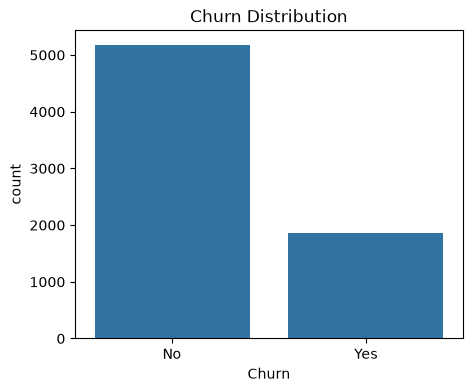

In [6]:
print(df["Churn"].value_counts(normalize=True))

plt.figure(figsize=(5, 4))
sns.countplot(data=df, x="Churn")
plt.title("Churn Distribution")
plt.savefig("../images/churn_distribution.png", bbox_inches="tight")
plt.show()

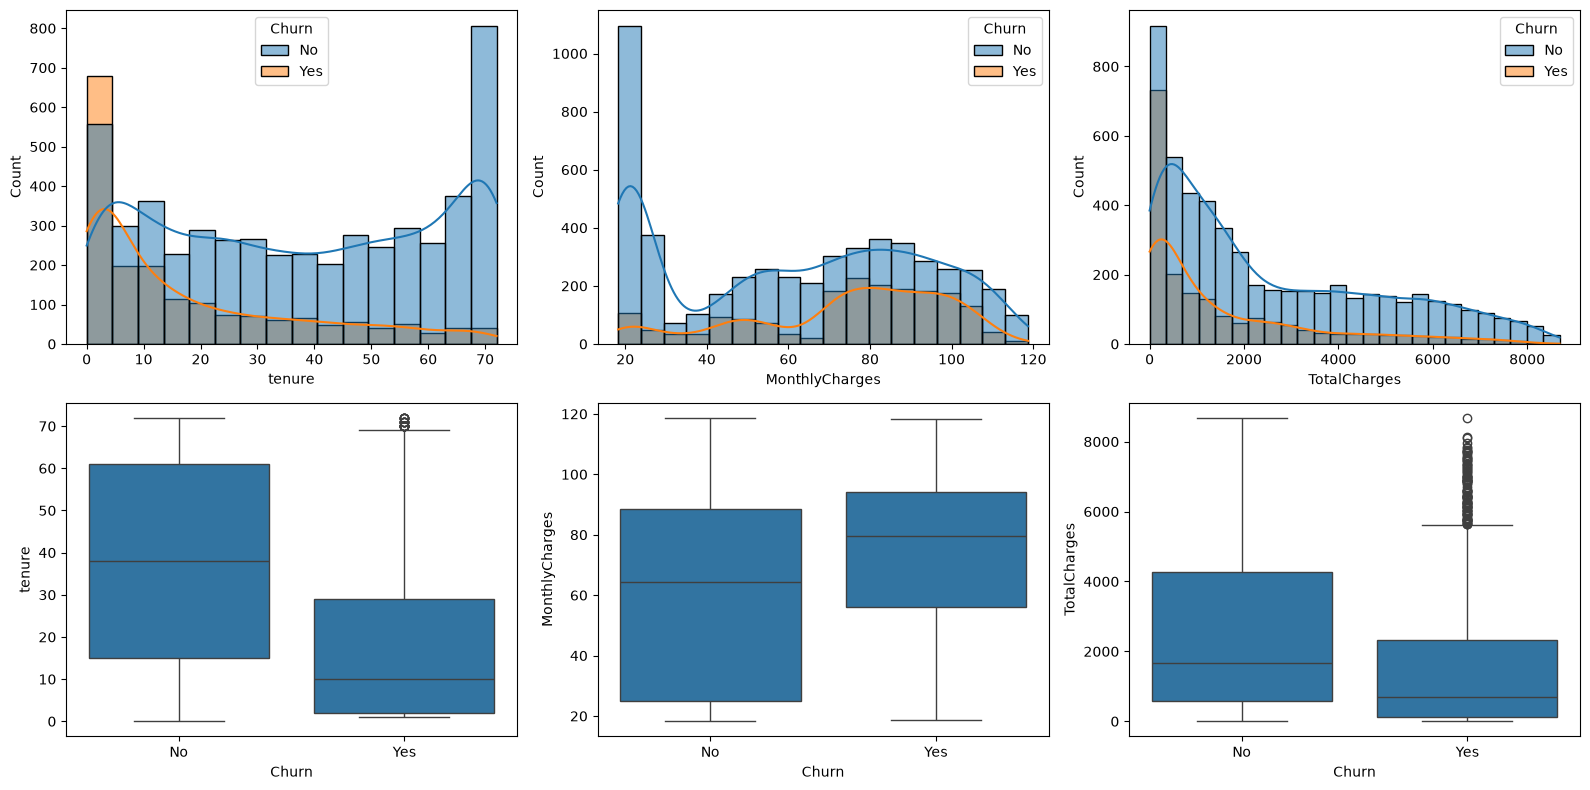

In [7]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, hue="Churn", kde=True, ax=axes[0, i])
    sns.boxplot(data=df, x="Churn", y=col, ax=axes[1, i])
plt.tight_layout()
plt.savefig("../images/numeric_vs_churn.png", bbox_inches="tight")
plt.show()

C:\Users\uthuni Fernando\AppData\Local\Temp\ipykernel_2240\3151927828.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = [c for c in df.select_dtypes("object").columns if c != "Churn"]


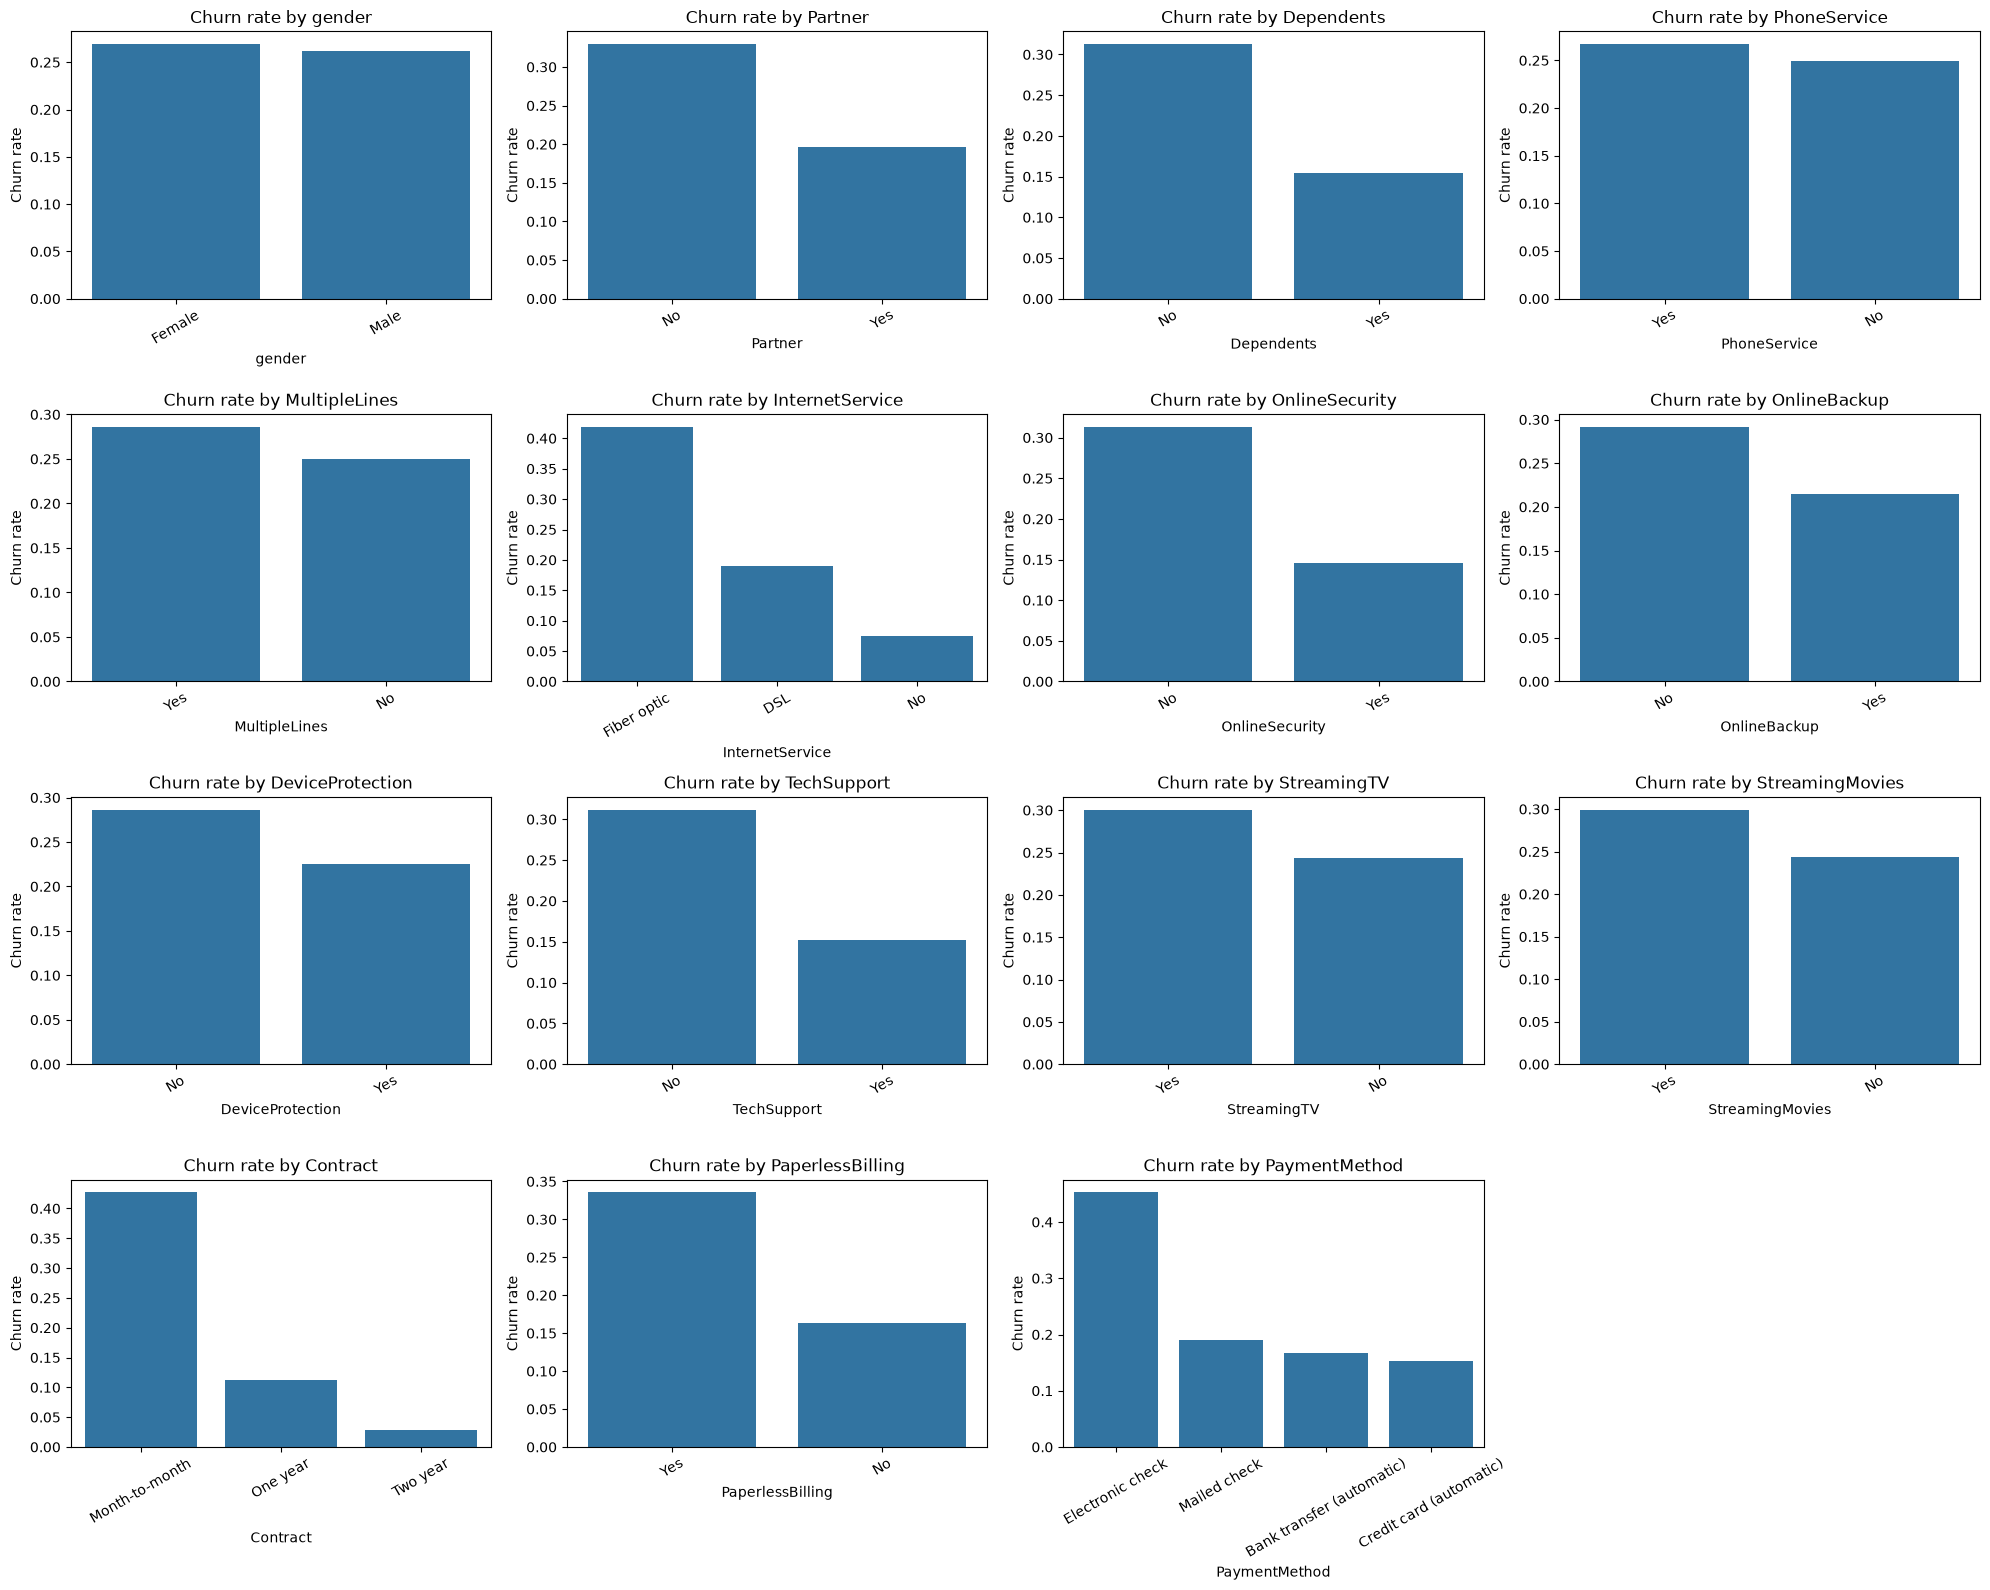

In [8]:
cat_cols = [c for c in df.select_dtypes("object").columns if c != "Churn"]

fig, axes = plt.subplots(4, 4, figsize=(20, 16))
axes = axes.flatten()
for i, col in enumerate(cat_cols):
    rate = df.groupby(col)["Churn_bin"].mean().sort_values(ascending=False)
    sns.barplot(x=rate.index, y=rate.values, ax=axes[i])
    axes[i].set_title(f"Churn rate by {col}")
    axes[i].set_ylabel("Churn rate")
    axes[i].tick_params(axis="x", rotation=30)
for j in range(len(cat_cols), len(axes)):
    axes[j].axis("off")
plt.tight_layout()
plt.savefig("../images/categorical_vs_churn.png", bbox_inches="tight")
plt.show()

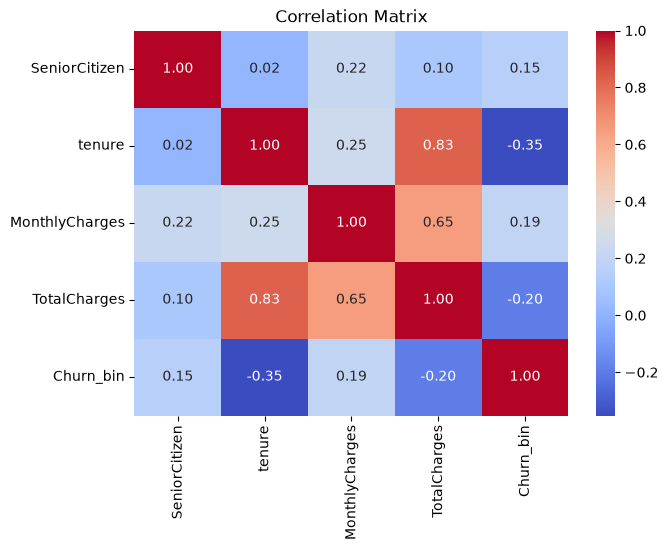

In [9]:
plt.figure(figsize=(7, 5))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.savefig("../images/correlation_heatmap.png", bbox_inches="tight")
plt.show()

In [10]:
for col in ["Contract", "InternetService", "PaymentMethod"]:
    print(df.groupby(col)["Churn_bin"].mean().sort_values(ascending=False).round(3), "\n")

df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                            labels=["0-12", "13-24", "25-48", "49-72"])
print(df.groupby("tenure_group", observed=True)["Churn_bin"].mean().round(3))

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn_bin, dtype: float64 

InternetService
Fiber optic    0.419
DSL            0.190
No             0.074
Name: Churn_bin, dtype: float64 

PaymentMethod
Electronic check             0.453
Mailed check                 0.191
Bank transfer (automatic)    0.167
Credit card (automatic)      0.152
Name: Churn_bin, dtype: float64 

tenure_group
0-12     0.474
13-24    0.287
25-48    0.204
49-72    0.095
Name: Churn_bin, dtype: float64


In [11]:
df.drop(columns=["tenure_group"]).to_csv("../data/clean_churn.csv", index=False)